# 03 – Feature engineering

This notebook builds the features that **all** models share. The code lives in `features.py`,
so every model notebook can simply call `build_features(...)` and gets exactly the same features.

What is *not* done here: imputation, scaling and one-hot encoding. Those depend on the model
(trees vs. logistic regression vs. FT-Transformer) and happen in the model notebooks.

Plan:
1. Look at the genres properly (they turned out to be `|`-separated, with ~3,900 distinct genres)
2. Look at the song titles
3. Build all features and see what they are
4. Show *why* target encoding must be done out-of-fold (leakage demo)
5. Compare every new feature with the baseline (`artist_followers`, AUC 0.8747)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

import features  # our own feature code, see features.py
from features import build_features, split_genres

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# same plot style as in notebook 01
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110,
})

# load data and attach the fixed split from notebook 02
train = pd.read_csv("train.csv").merge(pd.read_csv("results/splits.csv"), on="id")
test = pd.read_csv("test.csv")
dev, valid = train[train["is_valid"] == 0], train[train["is_valid"] == 1]

# the score to beat, from notebook 02
baseline_auc = pd.read_csv("results/baseline_scores.csv")["valid_auc"].max()
print(f"dev: {len(dev):,} rows | valid: {len(valid):,} rows | test: {len(test):,} rows | baseline AUC: {baseline_auc:.4f}")

dev: 280,040 rows | valid: 70,011 rows | test: 87,513 rows | baseline AUC: 0.8747


## 1. Genres
`artist_genres` is a list of genres separated by `|`, e.g. `'dance pop|pop|urban contemporary'`.
The genres belong to the **artist**, not to the individual song.

In [2]:
# turn the text into Python lists, then 'explode' them: one row per (song, genre) pair
genre_lists = split_genres(dev["artist_genres"])
song_genre_pairs = pd.DataFrame({"genre": genre_lists, "music_hit": dev["music_hit"]}).explode("genre").dropna()

genre_counts = song_genre_pairs["genre"].value_counts()
print("distinct genres:", genre_counts.size)
for k in [20, 100, 500, 1000]:
    print(f"  genres that appear on >= {k:4d} songs: {(genre_counts >= k).sum()}")

# how many genres do songs have?
print("\nnumber of genres per song (0 = missing):")
print(genre_lists.str.len().value_counts().sort_index().head(12).to_dict())

distinct genres: 3810
  genres that appear on >=   20 songs: 1705
  genres that appear on >=  100 songs: 560
  genres that appear on >=  500 songs: 135
  genres that appear on >= 1000 songs: 70

number of genres per song (0 = missing):
{0: 130181, 1: 62411, 2: 29841, 3: 21565, 4: 12898, 5: 12222, 6: 4649, 7: 1258, 8: 3138, 9: 1216, 10: 330, 11: 206}


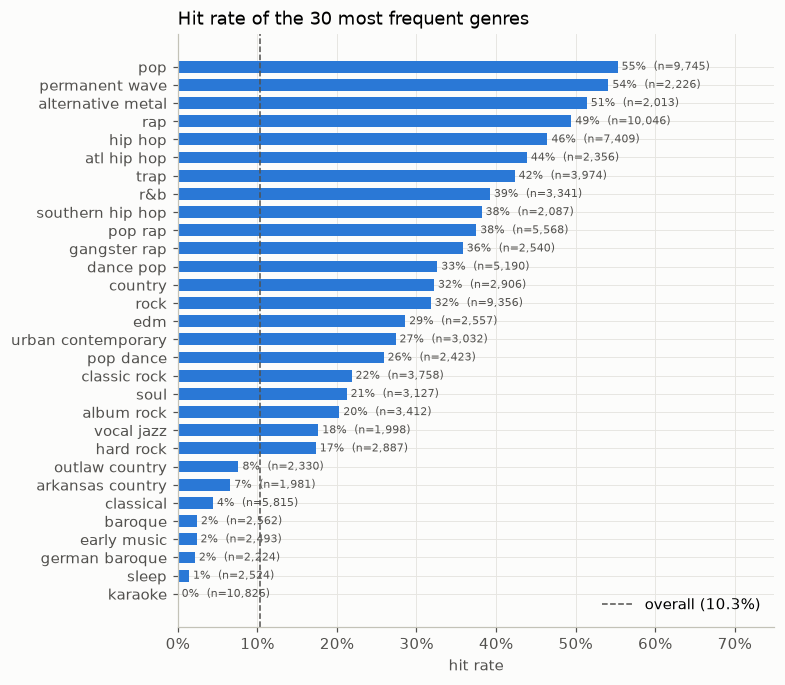

In [3]:
# hit rate of the 30 most frequent genres, sorted from lowest to highest
genre_stats = song_genre_pairs.groupby("genre")["music_hit"].agg(hit_rate="mean", songs="size")
top30 = genre_stats.loc[genre_counts.index[:30]].sort_values("hit_rate")

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top30.index, top30["hit_rate"], color=BLUE, height=0.65)
ax.axvline(dev["music_hit"].mean(), color=GREY, lw=1, ls="--", label=f"overall ({dev['music_hit'].mean():.1%})")
for i, (rate, n) in enumerate(zip(top30["hit_rate"], top30["songs"])):
    ax.text(rate + 0.005, i, f"{rate:.0%}  (n={n:,})", va="center", fontsize=7.5, color=GREY)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, 0.75); ax.set_xlabel("hit rate"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Hit rate of the 30 most frequent genres", loc="left")
plt.show()

**Interpretation.** Genre is a strong signal: karaoke, sleep and baroque are almost never hits, while pop, rap and hip hop are hits about half the time.
With ~3,900 genres we can't make a column for each one, so we use two representations:
- **multi-hot** for the 150 most frequent genres (one 0/1 column each). Easy to interpret and works for every model.
- **target encoding**: the average and maximum hit rate of a song's genres. This also captures rare genres.

The *number* of genres is also informative (AUC 0.77 on its own): well-known artists get more genre tags.

## 2. Song titles

In [4]:
# hit rate of songs whose title contains a keyword
title = dev["track_name"].fillna("").str.lower()
rows = []
for word in features.TITLE_KEYWORDS:
    has_word = title.str.contains(word, regex=False)
    rows.append({"keyword": word, "songs": has_word.sum(), "hit_rate": dev["music_hit"][has_word].mean()})
pd.DataFrame(rows).sort_values("hit_rate", ascending=False).round(3)

,keyword,songs,hit_rate
0,feat,8138,0.318
1,remaster,4055,0.212
2,remix,6790,0.137
3,live,7354,0.111
6,version,17086,0.044
7,cover,876,0.025
5,instrumental,7109,0.016
4,karaoke,10144,0.000


**Interpretation.** Collaborations ("feat.") and remasters of old classics are hits much more often.
Karaoke, instrumental and cover versions almost never are. Each keyword becomes a 0/1 feature.

## 3. Build all features
`build_features(fit_df, apply_dfs, all_rows)` learns everything that needs labels on `fit_df` (here: the dev set)
and applies it to the other DataFrames (validation and test).

In [5]:
# train + test inputs together, only used for label-free song counts
all_rows = pd.concat([train, test])

X_dev, (X_valid, X_test) = build_features(dev, [valid, test], all_rows)
print("X_dev:", X_dev.shape, "| X_valid:", X_valid.shape, "| X_test:", X_test.shape)

X_dev: (280040, 191) | X_valid: (70011, 191) | X_test: (87513, 191)


In [6]:
# overview: which features exist, grouped by type
groups = {
    "audio":             [c for c in X_dev.columns if c.startswith("audio_")] + ["time_signature", "duration_sec"],
    "artist popularity": ["log_followers"],
    "release date":      ["year", "month", "date_is_jan_1"],
    "album type / explicit": ["explicit", "album_type_album", "album_type_single", "album_type_compilation"],
    "title":             [c for c in X_dev.columns if c.startswith("title_")],
    "genre summary":     ["genres_missing", "n_genres"],
    "genre multi-hot":   [c for c in X_dev.columns if c.startswith("genre_") and not c.startswith("genre_te")],
    "song counts":       [c for c in X_dev.columns if c.endswith("_n_songs")],
    "target encodings":  [c for c in X_dev.columns if c.endswith("_te") or c.startswith("genre_te")],
}
for name, cols in groups.items():
    preview = ", ".join(cols[:6]) + (" ..." if len(cols) > 6 else "")
    print(f"{name:22s} {len(cols):4d} columns   {preview}")
print("total:", sum(len(c) for c in groups.values()), "columns")

audio                    13 columns   audio_dance, audio_energy, audio_key, audio_loudness, audio_mode, audio_speech ...
artist popularity         1 columns   log_followers
release date              3 columns   year, month, date_is_jan_1
album type / explicit     4 columns   explicit, album_type_album, album_type_single, album_type_compilation
title                    10 columns   title_has_feat, title_has_remaster, title_has_remix, title_has_live, title_has_karaoke, title_has_instrumental ...
genre summary             2 columns   genres_missing, n_genres
genre multi-hot         150 columns   genre_karaoke, genre_rap, genre_pop, genre_rock, genre_hip hop, genre_classical ...
song counts               3 columns   artist_name_n_songs, record_label_n_songs, album_name_n_songs
target encodings          5 columns   artist_name_te, record_label_te, album_name_te, genre_te_mean, genre_te_max
total: 191 columns


In [7]:
# remaining missing values (models must handle these)
X_dev.isna().mean()[lambda s: s > 0].round(3).to_frame("share missing")

,share missing
audio_tempo,0.002
time_signature,0.015
genre_te_mean,0.465
genre_te_max,0.465


Only the converted "hidden" missing values (tempo, time signature) and the genre target encodings
(songs without genres) are still NaN. Tree models handle NaN directly. Logistic regression and the FT-Transformer need imputation.

## 4. Why target encoding must be out-of-fold
Target encoding replaces e.g. an artist with the artist's hit rate. If we compute that hit rate with **all** dev songs
and then train on those same songs, every song's own label is already inside its feature value.
This is called **target leakage**. It matters most for small artists: an artist with a single song that is a hit gets a "hit rate" of 100 %.

With **out-of-fold** encoding, a song in fold k only gets the hit rate computed on the other 4 folds.
Below we compare both versions. A good feature should score about the same on dev as on validation.

In [8]:
# --- naive version (WRONG): hit rate per category computed from ALL dev songs, no smoothing ---
te_cols = ["artist_name", "record_label", "album_name"]
prior = dev["music_hit"].mean()

naive_dev, naive_valid = pd.DataFrame(), pd.DataFrame()
for col in te_cols:
    rates = dev.groupby(col)["music_hit"].mean()
    naive_dev[col] = dev[col].map(rates).fillna(prior).values
    naive_valid[col] = valid[col].map(rates).fillna(prior).values  # unknown category -> overall hit rate

# --- out-of-fold version (CORRECT): the columns built by features.py ---
oof_dev = X_dev[[f"{c}_te" for c in te_cols]]
oof_valid = X_valid[[f"{c}_te" for c in te_cols]]
print(oof_dev.head(3))

   artist_name_te  record_label_te  album_name_te
0        0.046990         0.014358       0.046990
1        0.039761         0.013602       0.039761
2        0.039761         0.013970       0.039761


Looking at a single feature isn't enough to see the damage. Leakage hurts when a **model is trained** on the leaky feature.
So we train a quick test model (scikit-learn's `HistGradientBoostingClassifier`, a fast tree ensemble)
on the three encodings plus `log_followers`, once with each version, and score it on dev and on validation.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier

def quick_model_auc(X_train, X_eval):
    """Train a small tree model on dev, return (AUC on dev, AUC on valid)."""
    X_train = X_train.assign(log_followers=X_dev["log_followers"].values)
    X_eval = X_eval.assign(log_followers=X_valid["log_followers"].values)
    model = HistGradientBoostingClassifier(random_state=SEED).fit(X_train, dev["music_hit"])
    auc_dev = roc_auc_score(dev["music_hit"], model.predict_proba(X_train)[:, 1])
    auc_valid = roc_auc_score(valid["music_hit"], model.predict_proba(X_eval)[:, 1])
    return auc_dev, auc_valid

SEED = 42
leak_demo = pd.DataFrame(
    [quick_model_auc(naive_dev, naive_valid), quick_model_auc(oof_dev, oof_valid)],
    index=["naive target encoding", "out-of-fold target encoding (features.py)"],
    columns=["AUC on dev (training data)", "AUC on valid"],
).round(4)
leak_demo

,AUC on dev (training data),AUC on valid
naive target encoding,0.9881,0.9294
out-of-fold target encoding (features.py),0.9663,0.9621


**Interpretation.**
- **Naive:** the model looks almost perfect on its own training data but loses a lot on validation.
  It learned "trust the encoding completely", which only works while the song's own label is inside the encoding.
- **Out-of-fold:** dev and validation scores are close together, and the **validation score is clearly higher**.
  This is the version we use.

*Side note:* we also tried smoothing values of 1, 5 and 20. The validation AUC changed by less than 0.002, so we kept 5.

## 5. New features vs. the baseline
Validation AUC of each important feature on its own (higher values → more hits, so no direction flip needed).

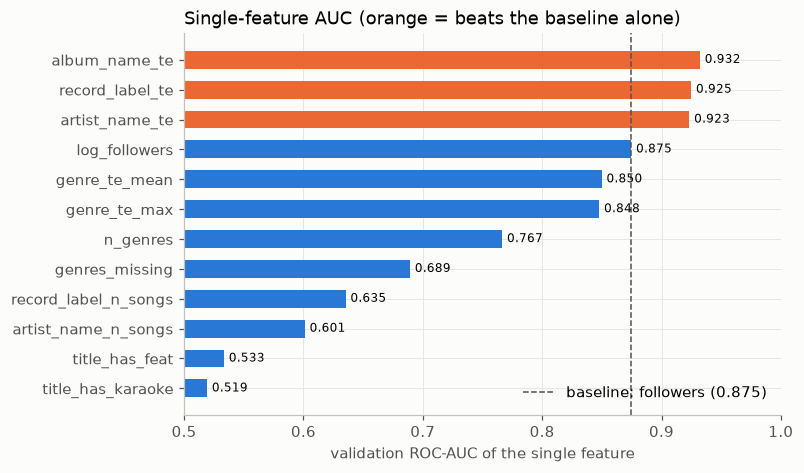

In [10]:
check_cols = ["album_name_te", "record_label_te", "artist_name_te", "genre_te_mean", "genre_te_max",
              "log_followers", "n_genres", "genres_missing", "record_label_n_songs", "artist_name_n_songs",
              "title_has_feat", "title_has_karaoke"]

single_auc = {}
for col in check_cols:
    auc = roc_auc_score(valid["music_hit"], X_valid[col].fillna(-1))  # NaN (no genre) -> lowest score
    single_auc[col] = max(auc, 1 - auc)
single_auc = pd.Series(single_auc).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = [ORANGE if v > baseline_auc else BLUE for v in single_auc.values]
ax.barh(single_auc.index, single_auc.values - 0.5, left=0.5, color=colors, height=0.6)
ax.axvline(baseline_auc, color=GREY, lw=1, ls="--", label=f"baseline: followers ({baseline_auc:.3f})")
for i, v in enumerate(single_auc.values):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(0.5, 1.0); ax.set_xlabel("validation ROC-AUC of the single feature")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Single-feature AUC (orange = beats the baseline alone)", loc="left")
plt.show()

**Interpretation.** The three target encodings (album, label, artist) each beat the baseline **on their own**,
with AUC around 0.91–0.93. A song's context (who released it, on which label and album) says more than any audio feature.
The models now have to show they can combine these features and beat the best single one.

## Summary: preprocessing needed per model
| | Logistic regression | Random Forest / LightGBM | FT-Transformer |
|---|---|---|---|
| NaN (tempo, time sig., genre TE) | impute median + missing flag | keep NaN (LightGBM) / impute (RF) | impute median + missing flag |
| Scaling | `StandardScaler` | not needed | standardize (or quantile transform) |
| Skewed counts (`*_n_songs`) | `log1p` | not needed | `log1p` |
| Genre multi-hot (150 cols) | as is | as is | as is (or one embedding per genre) |